In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from PIL import Image

import src.pibisa
from src.models import ResNET_emb

In [2]:
if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

torch.manual_seed(0)

transform = torchvision.transforms.Compose(
    [
        torchvision.transforms.Resize((224, 224)),
        torchvision.transforms.ToTensor(),
    ]
)

In [3]:
pil_img1 = Image.open("./toy_images/test_image4.JPEG").convert("RGB")
pil_img2 = Image.open("./toy_images/test_image2.JPEG").convert("RGB")

img1 = transform(pil_img1)
img2 = transform(pil_img2)

x1 = torchvision.transforms.Normalize(
    mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
)(img1)
x2 = torchvision.transforms.Normalize(
    mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
)(img2)

x1 = x1[None, ...].to(device)
x2 = x2[None, ...].to(device)


In [4]:
model = ResNET_emb(level="full")
model = model.to(device)
model.eval()

config = src.pibisa.PibisaConfig(beta=1, phi=1, device=device)
pibisa = src.pibisa.PibisaAtt(model.forward, config)

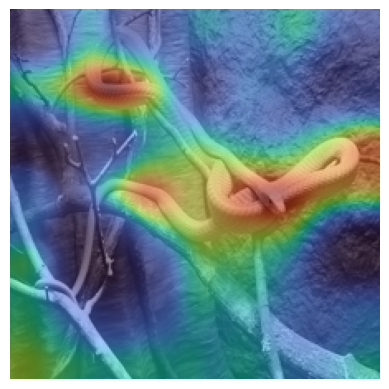

In [5]:
saliency_pos = pibisa.compute_attribution(
    query_image=x1, target_emb=model.forward(x1)
)

plt.imshow(pil_img1.resize((224, 224)).convert("L"), cmap="gray")
plt.imshow(np.squeeze(saliency_pos), cmap="turbo", alpha=0.5)
plt.axis("off")
plt.show()

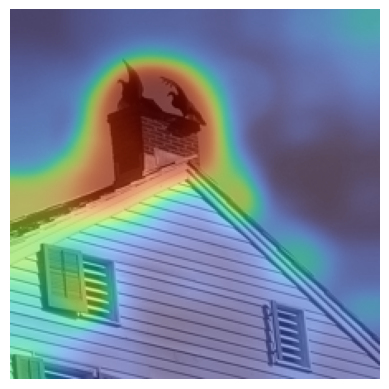

In [ ]:
saliency_pos = pibisa.compute_attribution(
    query_image=x2, target_emb=model.forward(x2)
)

plt.imshow(pil_img2.resize((224, 224)).convert("L"), cmap="gray")
plt.imshow(np.squeeze(saliency_pos), cmap="turbo", alpha=0.5)
plt.axis("off")
plt.show()

In [9]:
# Increasing the value of beta
config = src.pibisa.PibisaConfig(beta=10, phi=1, device=device)
pibisa = src.pibisa.PibisaAtt(model.forward, config)

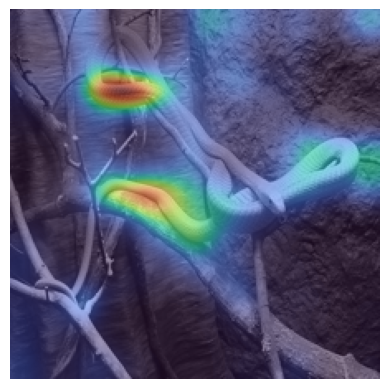

In [10]:
saliency_pos = pibisa.compute_attribution(
    query_image=x1, target_emb=model.forward(x1)
)

plt.imshow(pil_img1.resize((224, 224)).convert("L"), cmap="gray")
plt.imshow(np.squeeze(saliency_pos), cmap="turbo", alpha=0.5)
plt.axis("off")
plt.show()

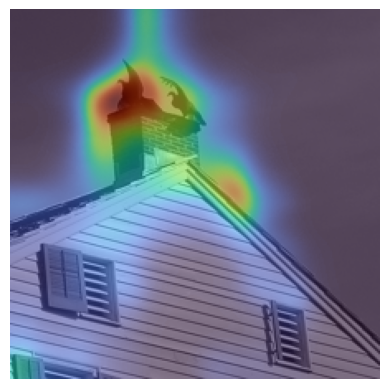

In [12]:
saliency_pos = pibisa.compute_attribution(
    query_image=x2, target_emb=model.forward(x2)
)

plt.imshow(pil_img2.resize((224, 224)).convert("L"), cmap="gray")
plt.imshow(np.squeeze(saliency_pos), cmap="turbo", alpha=0.5)
plt.axis("off")
plt.show()